In [8]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from dask.diagnostics.progress import ProgressBar

In [9]:
%cd /jetfs/home/gbrack/MSC_Thesis/analysis/process_fp_output/

/jetfs/home/gbrack/MSC_Thesis/analysis/process_fp_output


In [ ]:
flexpart_output_dir = Path(Path("pathnames").read_text().strip())
est_mse_change = pd.read_csv(
    flexpart_output_dir / "estimated_mse_change.csv",
    index_col="release",
    parse_dates=["initial_time", "release_time"]
)

In [15]:
old_workflow = pd.read_csv("old_workflow.csv")

In [11]:
delta_cpT = est_mse_change.cpT_end - est_mse_change.cpT_ini_raw / est_mse_change.weight_sum
delta_Lvq = est_mse_change.Lvq_end - est_mse_change.Lvq_ini_raw / est_mse_change.weight_sum
delta_gh = est_mse_change.gh_end - est_mse_change.gh_ini_raw / est_mse_change.weight_sum

est_mse_change["delta_cpT"] = delta_cpT
est_mse_change["delta_Lvq"] = delta_Lvq
est_mse_change["delta_gh"] = delta_gh

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards')

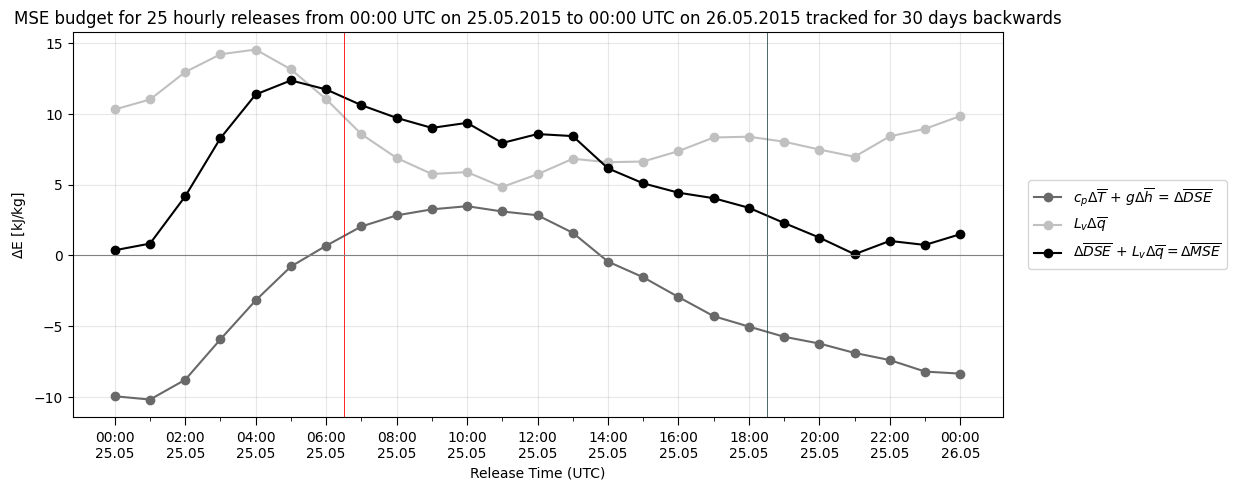

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

release_time = pd.to_datetime(est_mse_change.release_time)
label_every = 2

ax.plot(release_time, 
        (est_mse_change.delta_cpT + est_mse_change.delta_gh) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(release_time,
        est_mse_change.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(release_time,
        est_mse_change.delta_mse_est / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

day = release_time.iloc[0].normalize()
ax.axvline(day + pd.Timedelta(hours=6, minutes=30),
           color="red", linewidth=0.6)
ax.axvline(day + pd.Timedelta(hours=18, minutes=30),
           color="darkslategrey", linewidth=0.6)
ax.set_xticks(release_time.iloc[::label_every])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m"))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Release Time (UTC)")

ax.axhline(0, color="gray", linewidth=0.8)
#ax.grid(axis="y", alpha=0.3)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards")

In [18]:
with xr.open_dataset(flexpart_output_dir / "surface_maps.nc", chunks={}) as maps:
    totals = (
        maps[["sfc_sensible", "sfc_latent"]]
        .sum(
            dim=["hours_before_release", "latitude", "longitude"],
            skipna=False,
            dtype=np.float64
        )
    )

    with ProgressBar():
        totals = totals.compute()

    surface_budget_check = totals.to_dataframe()[["sfc_sensible", "sfc_latent"]]

surface_budget_check["sfc_total"] = (
    surface_budget_check.sfc_sensible + surface_budget_check.sfc_latent
)

display(surface_budget_check / 1000)

[########################################] | 100% Completed | 58.03 s


,sfc_sensible,sfc_latent,sfc_total
release,,,
1,7.767638,16.591798,24.359437
2,8.112062,16.984612,25.096674
3,8.073196,17.370272,25.443468
4,10.139087,18.082285,28.221372
5,11.503653,18.201230,29.704883
6,13.329734,17.632833,30.962567
7,13.331454,17.252868,30.584322
8,13.555315,17.547543,31.102858
9,13.736970,17.619091,31.356061


Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards')

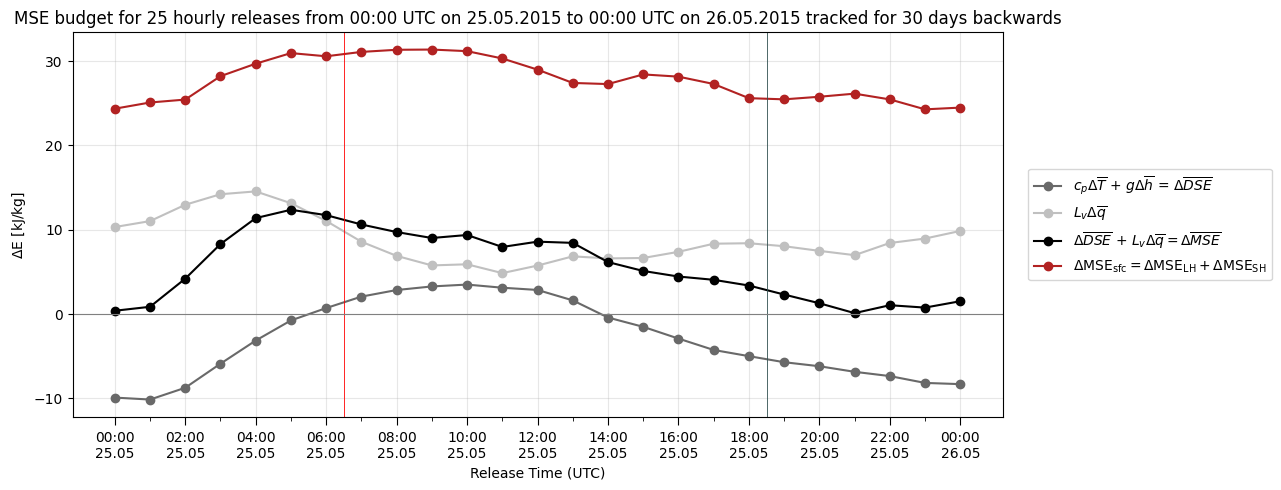

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

release_time = pd.to_datetime(est_mse_change.release_time)
label_every = 2

ax.plot(release_time, 
        (est_mse_change.delta_cpT + est_mse_change.delta_gh) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(release_time,
        est_mse_change.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(release_time,
        est_mse_change.delta_mse_est / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)
ax.plot(release_time,
        surface_budget_check.sfc_total / 1000,
        marker="o", 
        color="firebrick",
        label=r"$\Delta \mathrm{MSE}_{\mathrm{sfc}}"
                r" = \Delta \mathrm{MSE}_{\mathrm{LH}} + \Delta \mathrm{MSE}_{\mathrm{SH}}$",)

day = release_time.iloc[0].normalize()
ax.axvline(day + pd.Timedelta(hours=6, minutes=30),
           color="red", linewidth=0.6)
ax.axvline(day + pd.Timedelta(hours=18, minutes=30),
           color="darkslategrey", linewidth=0.6)
ax.set_xticks(release_time.iloc[::label_every])
ax.set_xticks(release_time, minor=True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M\n%d.%m"))
ax.tick_params(axis="x", which="major", length=6)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Release Time (UTC)")

ax.axhline(0, color="gray", linewidth=0.8)
#ax.grid(axis="y", alpha=0.3)
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 30 days backwards")

In [19]:
budget = est_mse_change.join(surface_budget_check)

In [34]:
sanity_check = budget.sfc_total.to_numpy() - old_workflow.sfc_total.to_numpy()